In [1]:
# Ensure we are running from the project root so all relative paths work
import os
from gbheatmodel.path import PROJECT_ROOT

os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from gbheatmodel.runner import (
    run_heat_demand_pipeline,
    run_heat_profiles_only,
)
from gbheatmodel.HD_Plots import (
    plot_daily_avg_profile_one_grid,
    plot_heatmap_one_grid,
    plot_total_daily_demand,
    plot_week_of_heat_profiles,
    plot_boxplot_half_hourly_distribution,
    plot_selected_grids_daily_demand,
    plot_tech_heatmaps,
    plot_area_full_year,
    plot_area_one_week,
    plot_area_full_year,
    
)

from gbheatmodel.path import path_in_data
from gbheatmodel.weather_inputs import ensure_weather_inputs

In [ ]:
# 🔧 User inputs for heating demand pipeline

weather_year = 2010        # weather data / patterns year
future_year = 2050         # target future year
FES_year = "2022"          # FES dataset version
FES_scenario = "LW"        # "LW", "CT", "ST", "FS", ...

In [ ]:

# Automatically prepare weather inputs for the selected model weather year.
# Existing files are reused; missing inputs are downloaded from Zenodo
# into the standard GBHeat data directories before the pipeline runs.
weather_data = ensure_weather_inputs(weather_year)

print("Weather inputs ready:", weather_data["year"])
print("Data directory:", weather_data["root"])
print("Grid patterns:", weather_data["found_patterns"])


In [ ]:
# Optional: a grid to inspect later
grid_id = "-3.5_56.0"

In [4]:
# Run the pipeline (fast if profiles already exist)
HD_profiles = run_heat_profiles_only(
    weather_year=weather_year,
    future_year=future_year,
    FES_year=FES_year,
    scenario=FES_scenario,
)
HD_profiles


✅ All heating profiles already exist. Loading from disk.


{'-0.25_50.75':                              ASHP          GSHP  Gas boiler  Electric storage  \
 2050-01-01 00:00:00  11258.656639  15142.824977    0.022245       4376.303568   
 2050-01-01 00:30:00  11432.756879  15437.775982    0.022006       4486.229197   
 2050-01-01 01:00:00  11802.194533  15943.044839    0.022637       4635.323729   
 2050-01-01 01:30:00  12099.466932  16334.350117    0.023235       4743.733143   
 2050-01-01 02:00:00  12677.736886  17028.991398    0.025089       4909.253344   
 ...                           ...           ...         ...               ...   
 2050-12-31 21:30:00  14402.341976  17189.354432    0.051773       4122.869771   
 2050-12-31 22:00:00  12691.523364  15534.608607    0.041675       3898.181379   
 2050-12-31 22:30:00  11018.155385  13926.605301    0.031541       3683.023992   
 2050-12-31 23:00:00   9766.808681  12727.154130    0.023863       3523.024767   
 2050-12-31 23:30:00   9140.282869  12152.912254    0.019718       3460.363473   
 

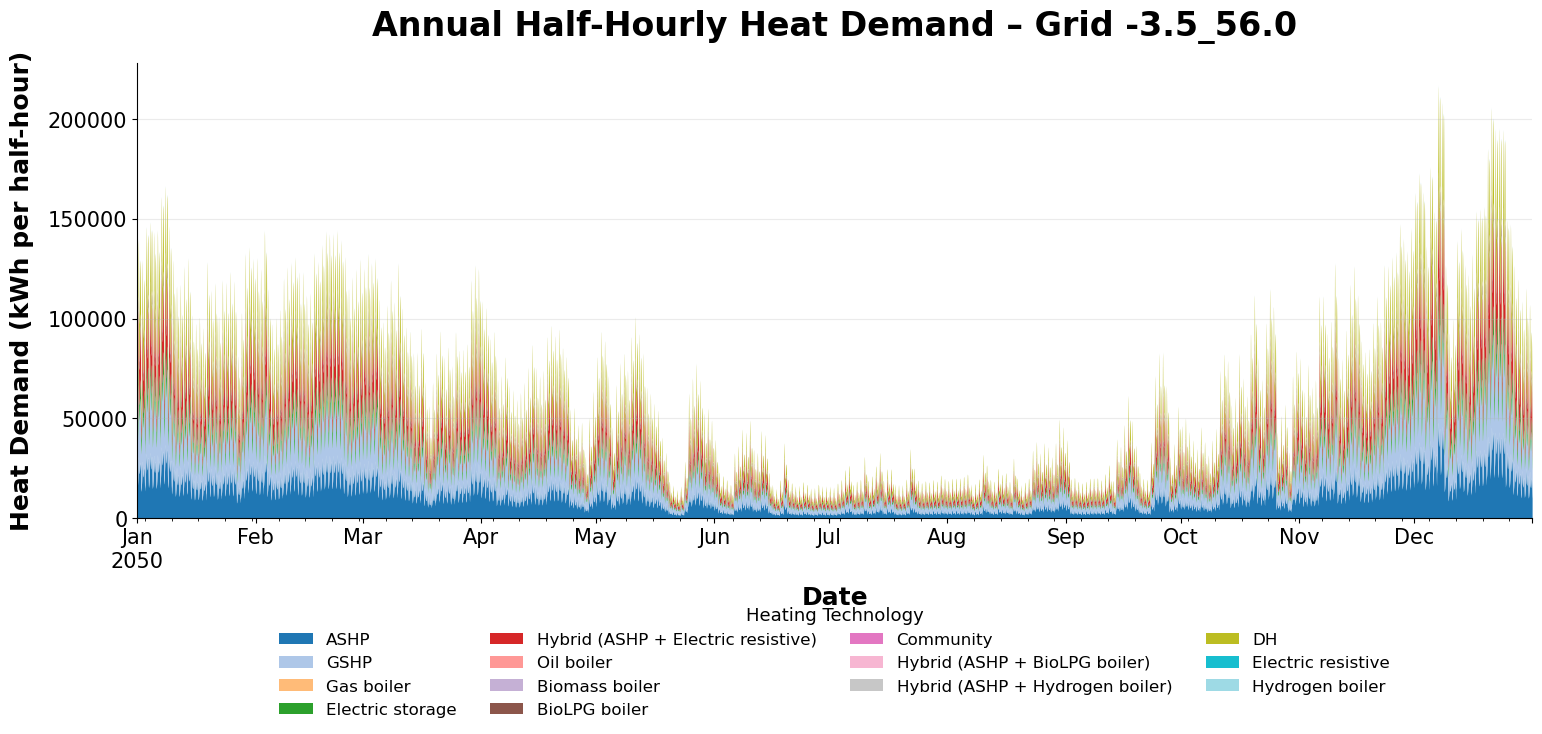

In [5]:
plot_area_full_year(HD_profiles, grid_id=grid_id)

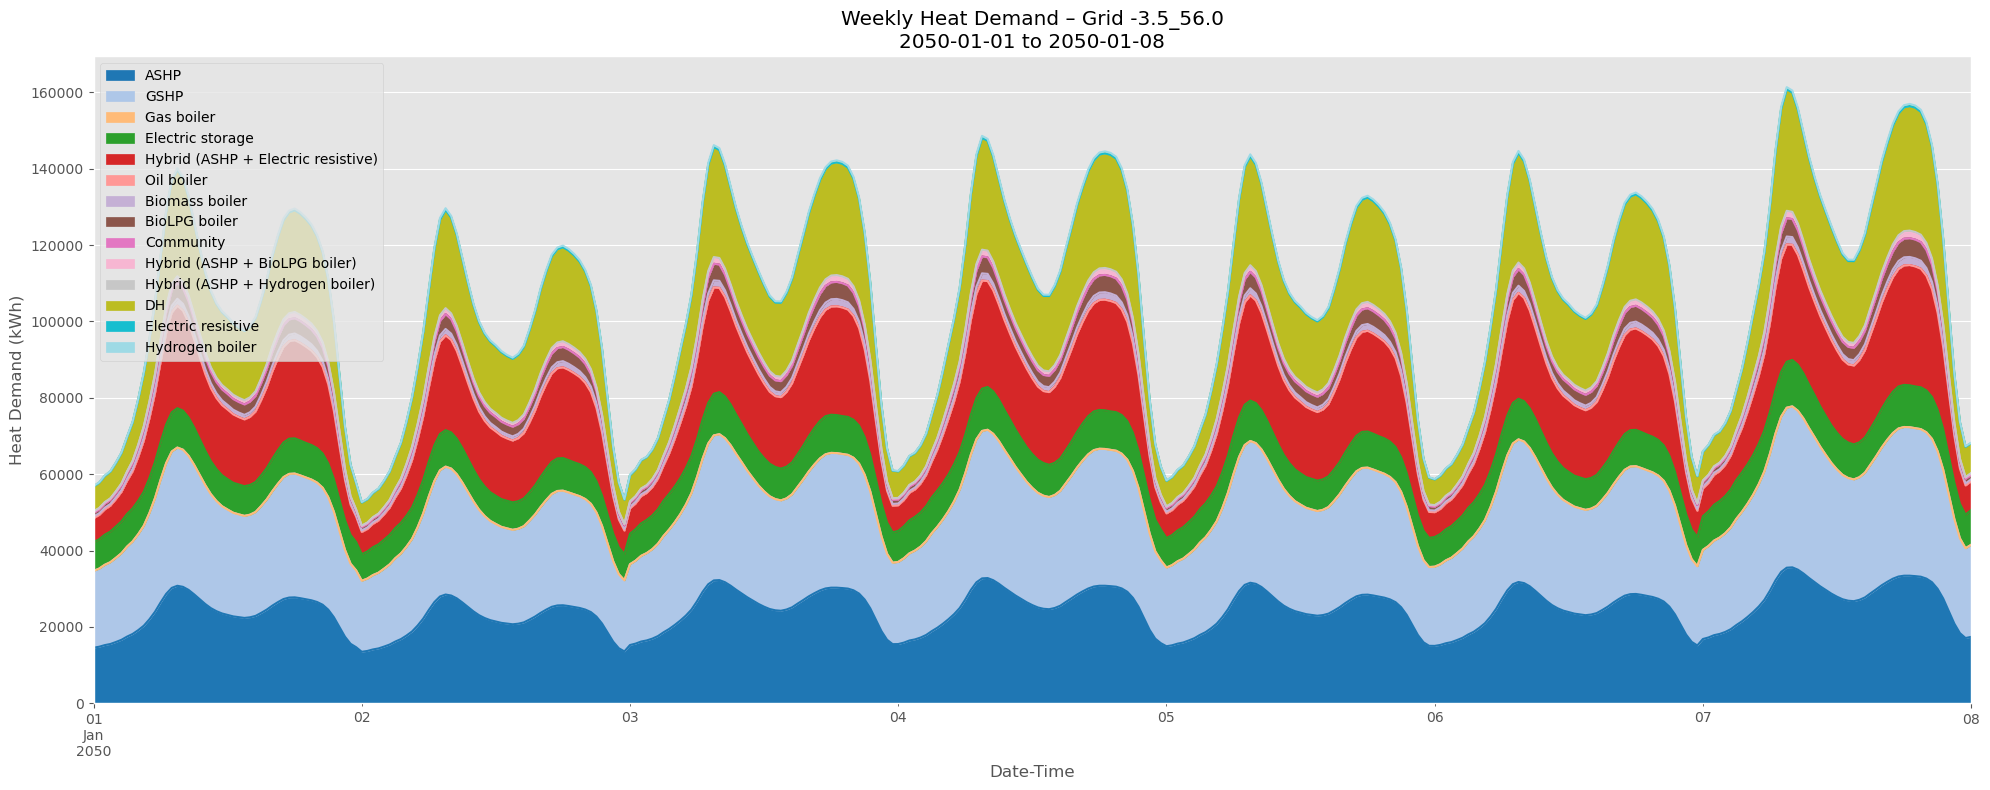

In [6]:
plot_area_one_week(
    HD_profiles,
    grid_id=grid_id,
    start_date="2050-01-01",
    days=7,
)

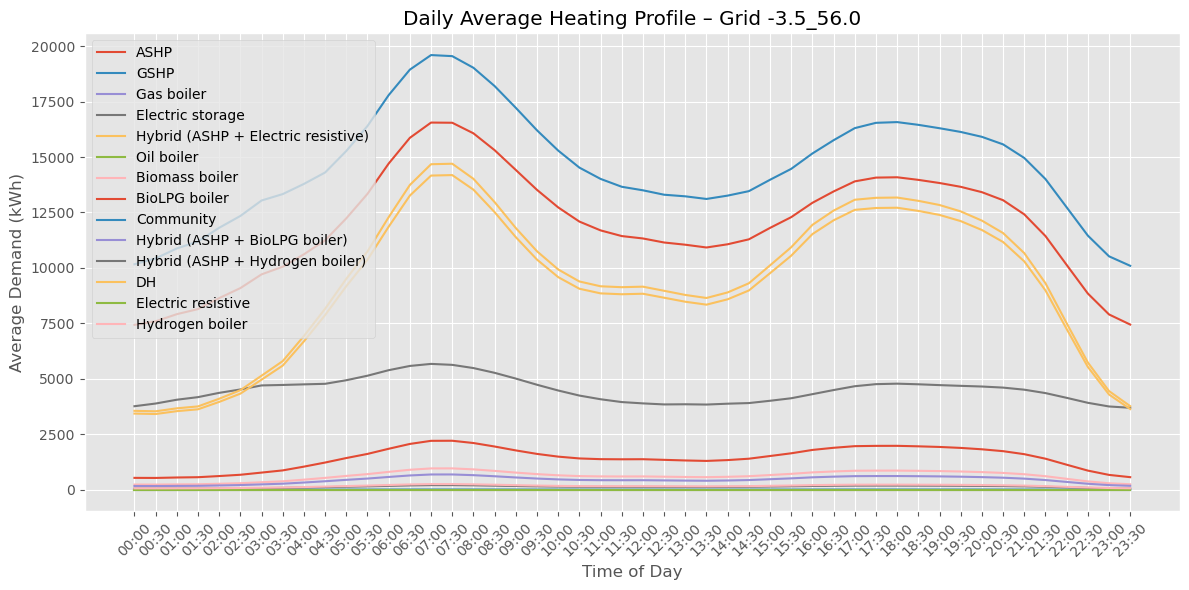

In [7]:
plot_daily_avg_profile_one_grid(
    HD_profiles,
    grid_id=grid_id,
    save=False,
)

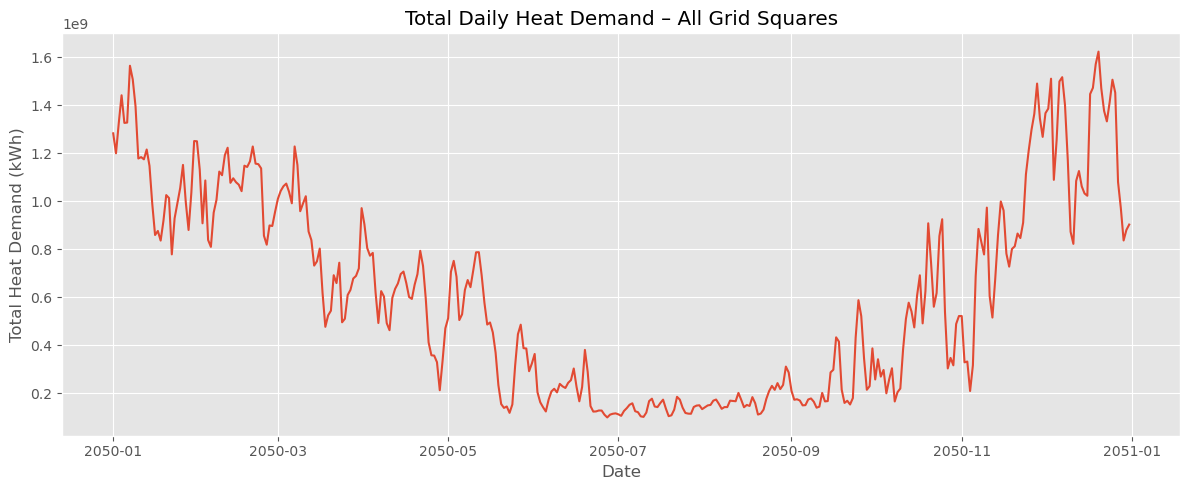

In [8]:
plot_total_daily_demand(HD_profiles, grid_id=None)

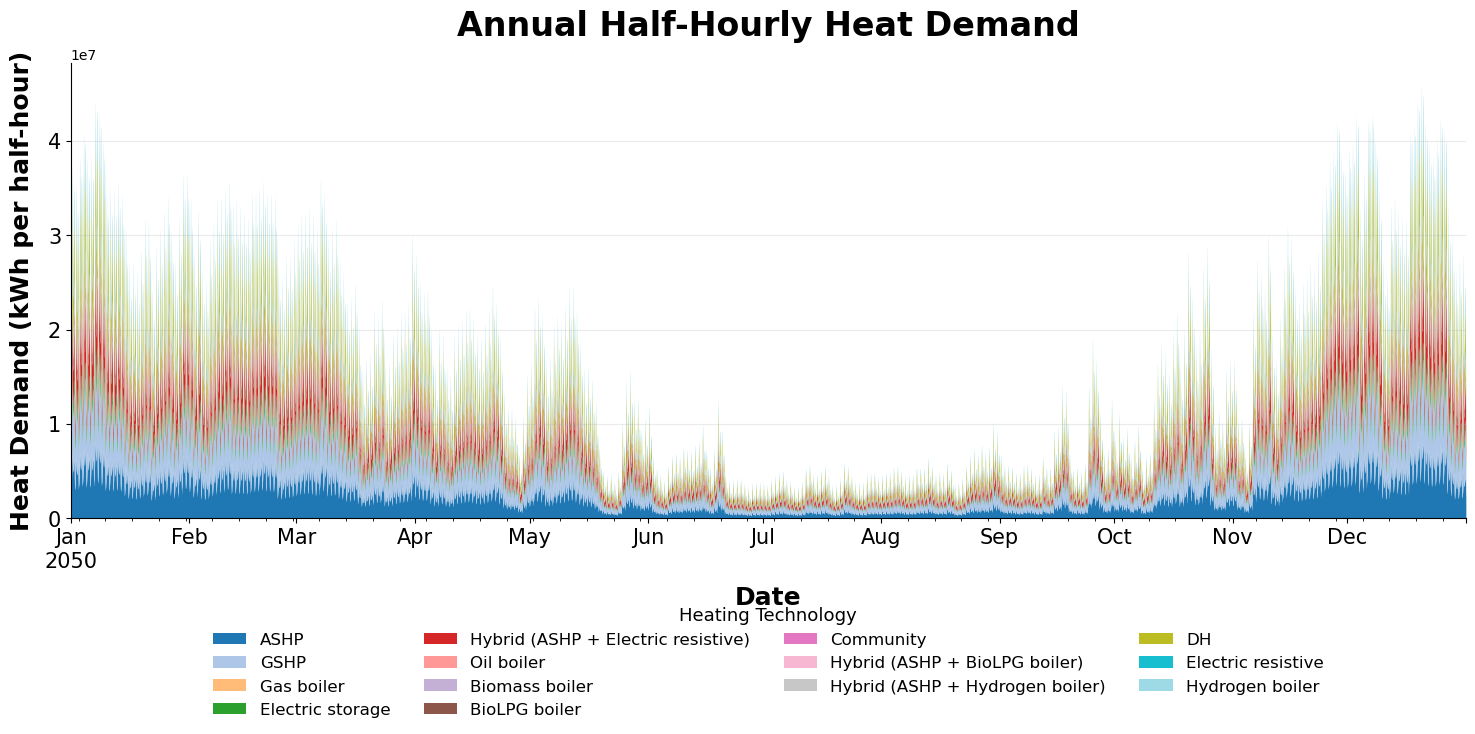

In [9]:
plot_area_full_year(HD_profiles, grid_id=None)

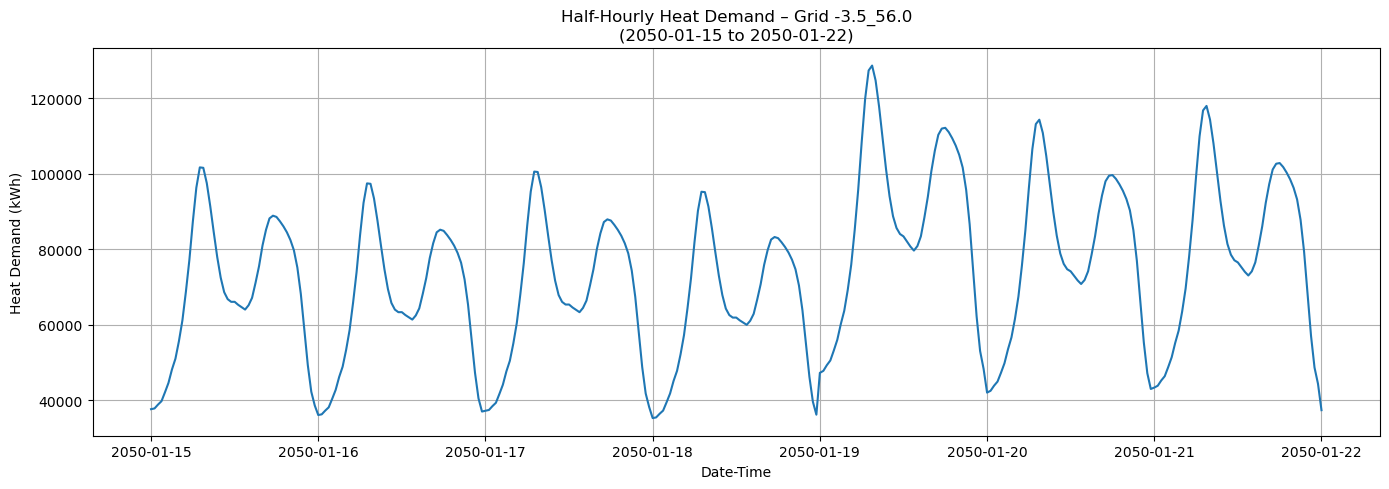

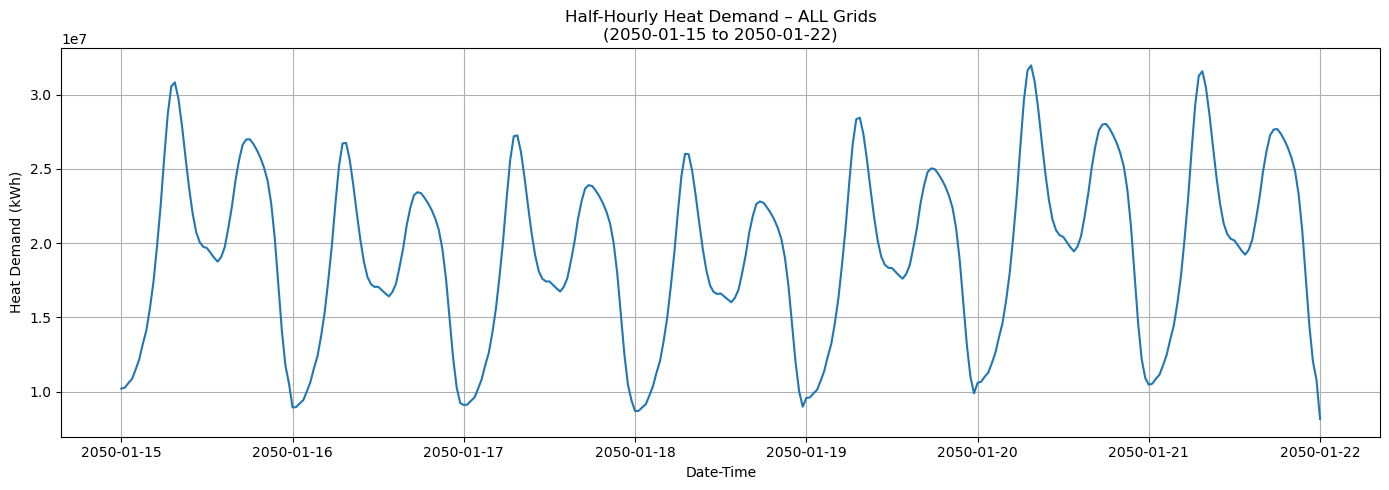

In [10]:
plot_week_of_heat_profiles(
    HD_profiles,
    grid_id=grid_id,
    start_date="2050-01-15",
    days=7,
)


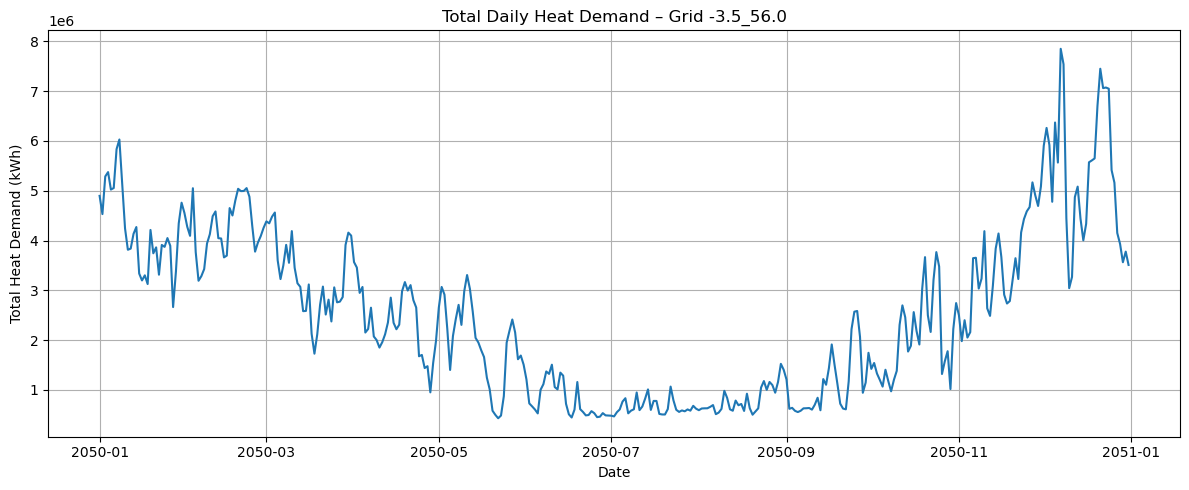

In [11]:
plot_total_daily_demand(
    HD_profiles,
    grid_id=grid_id,
    save=False,
)

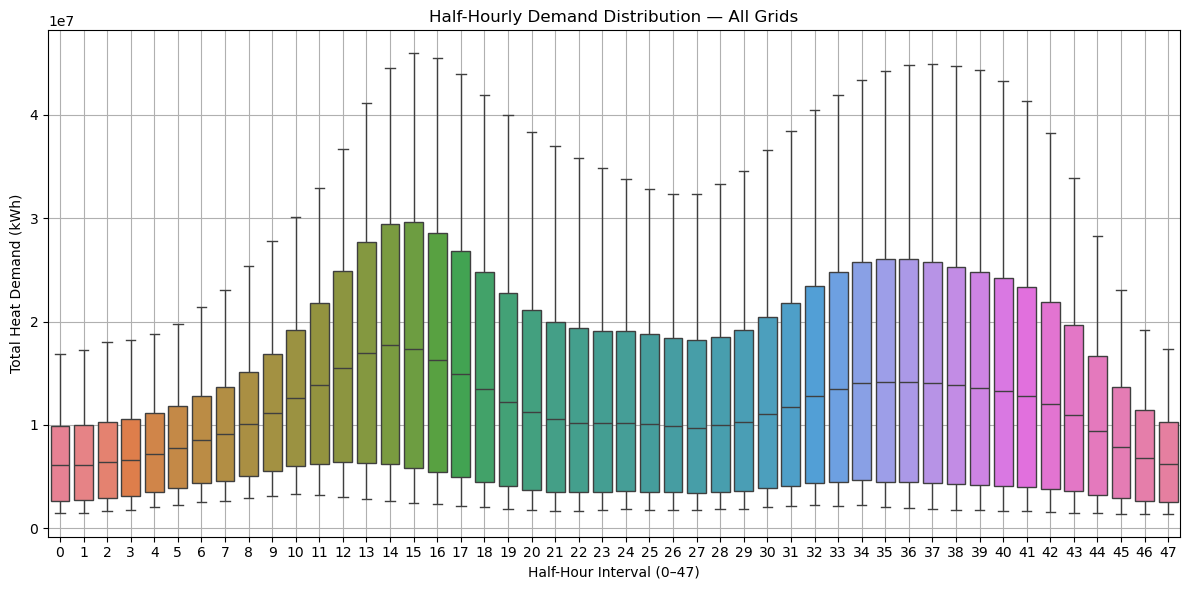

In [12]:
plot_boxplot_half_hourly_distribution(
    HD_profiles,
    grid_ids=None,  # None = all grids, or a list of several grid IDs[grid_id]
)

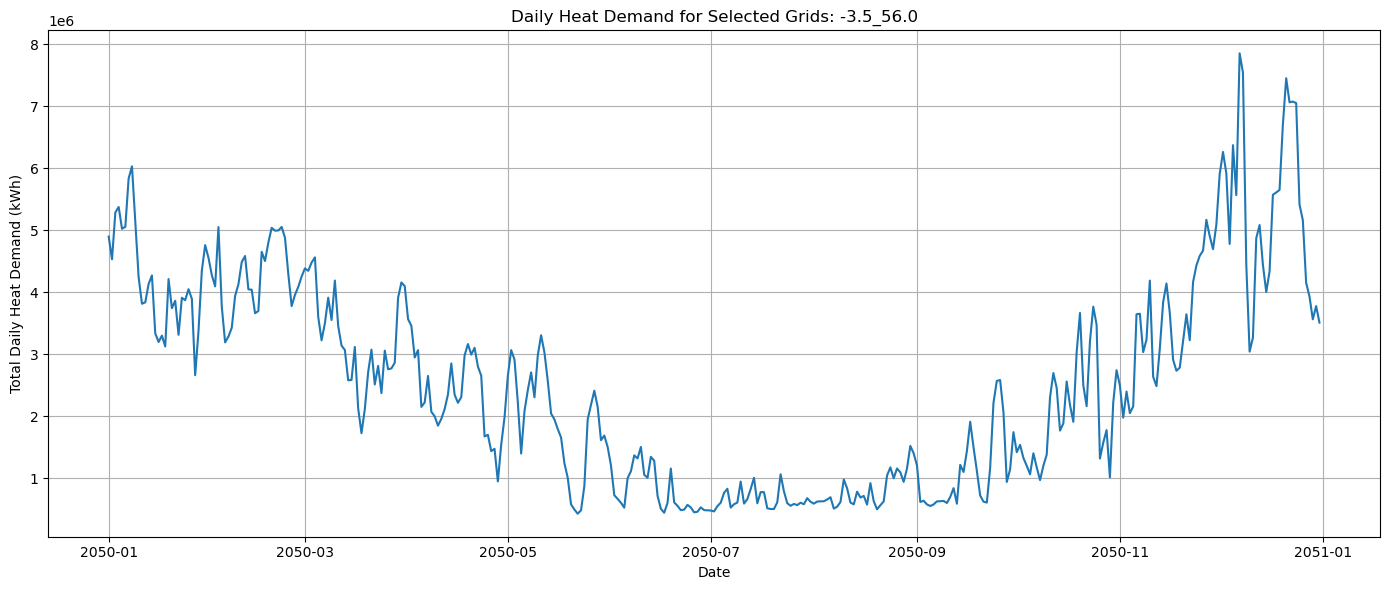

,-3.5_56.0
0,4.897893e+06
1,4.531964e+06
2,5.287634e+06
3,5.375213e+06
4,5.024397e+06
...,...
360,4.152791e+06
361,3.932779e+06
362,3.564866e+06
363,3.778235e+06


In [13]:
plot_selected_grids_daily_demand(
    HD_profiles,
    grid_ids=[grid_id],  # you can pass several: [grid_id]
    save=False,          # keep False, save=True has a small filename bug
)

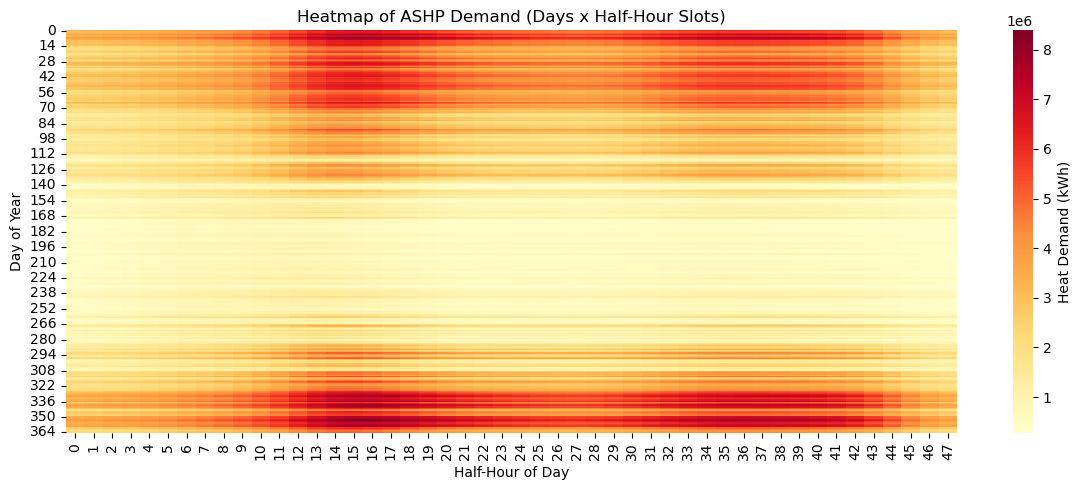

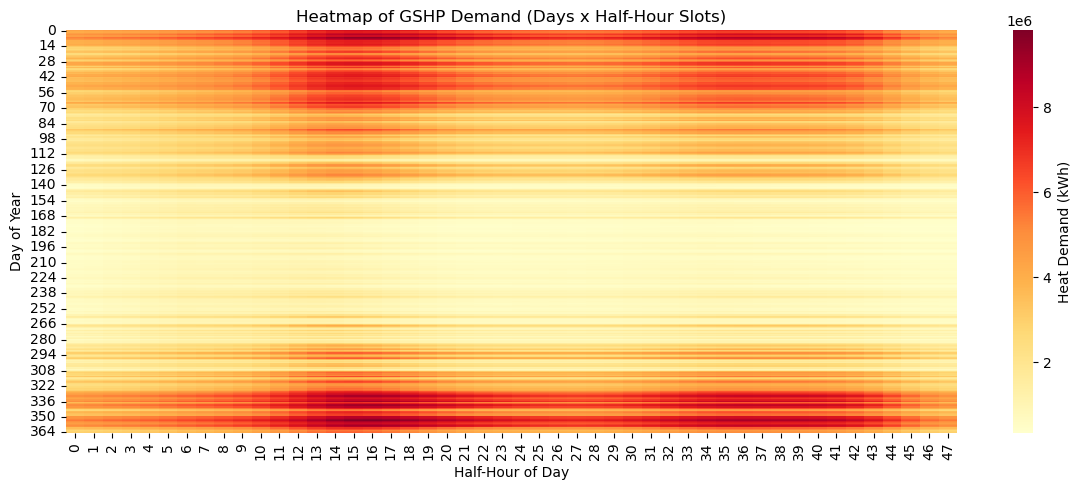

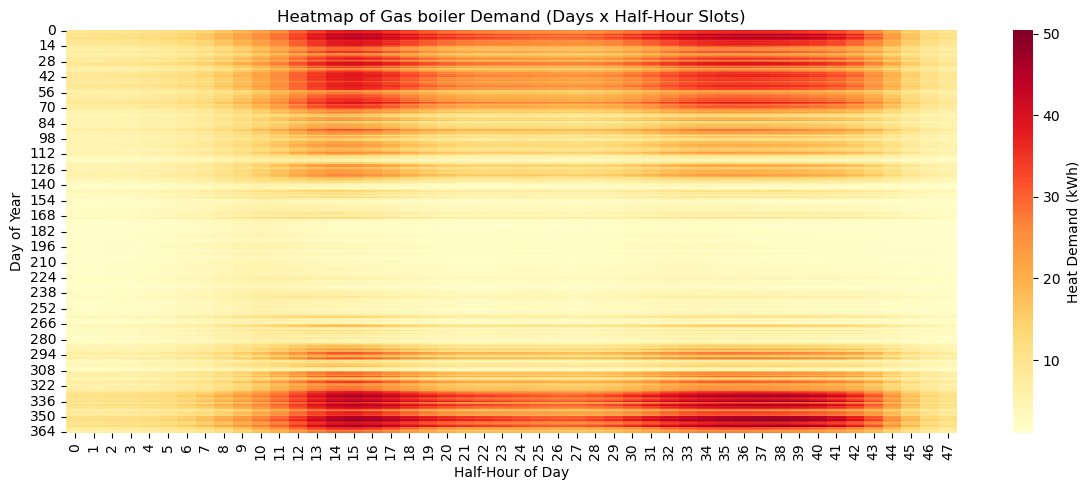

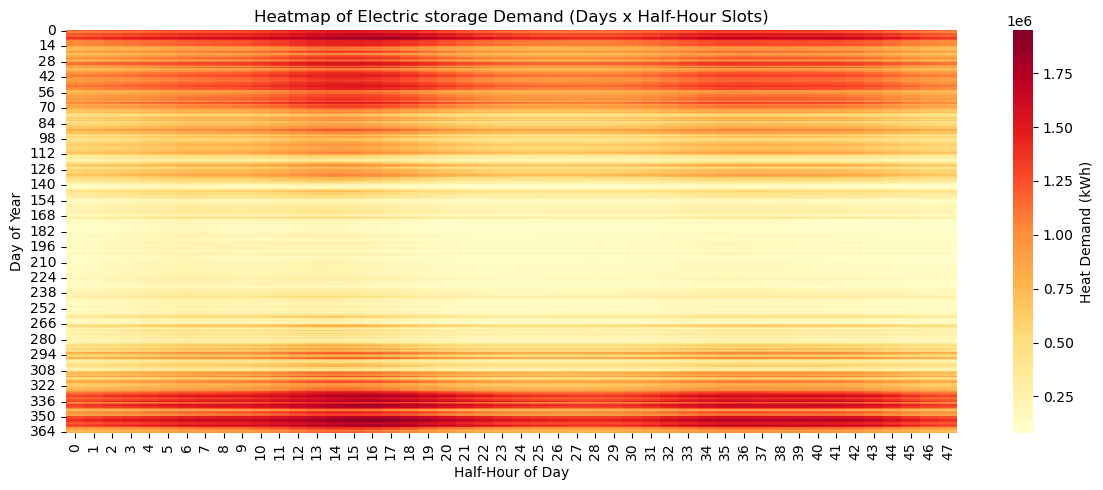

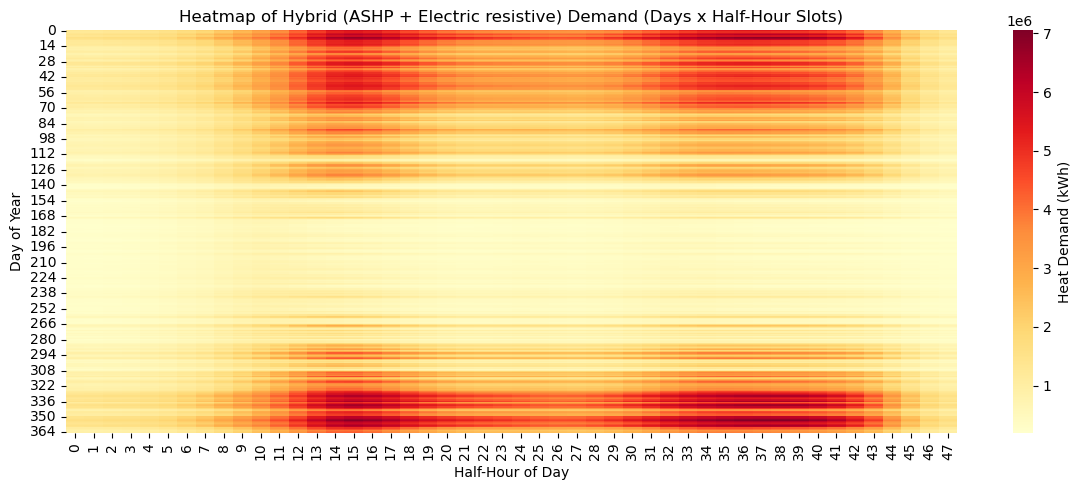

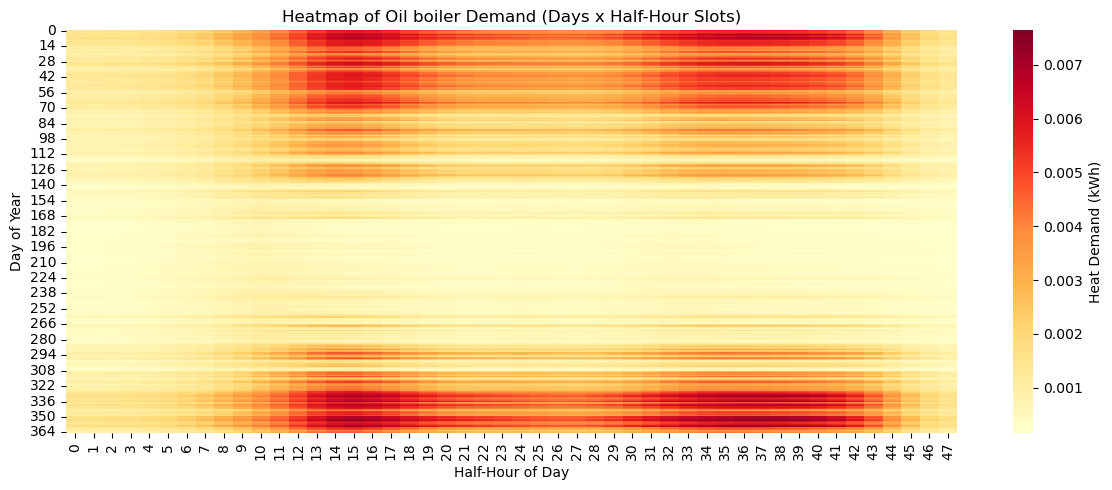

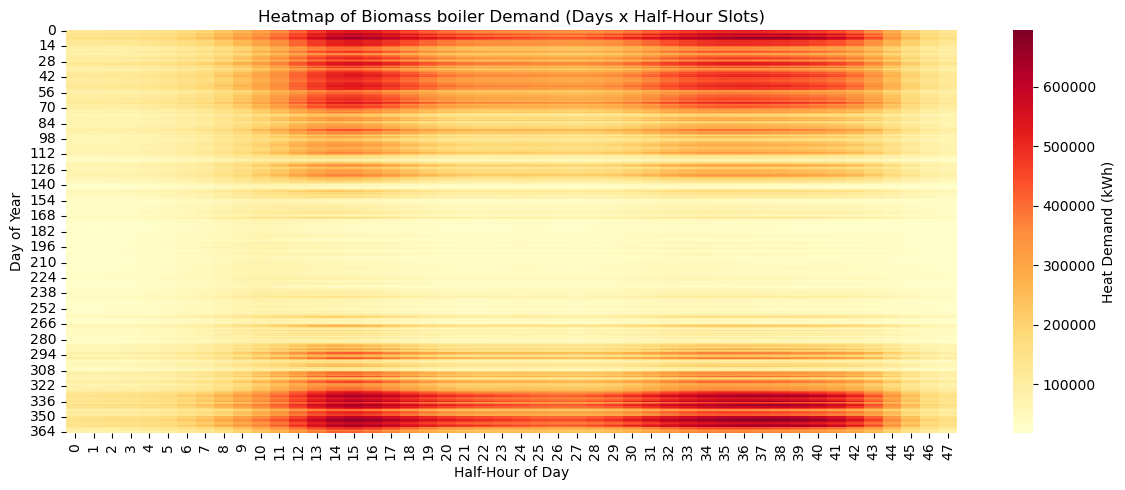

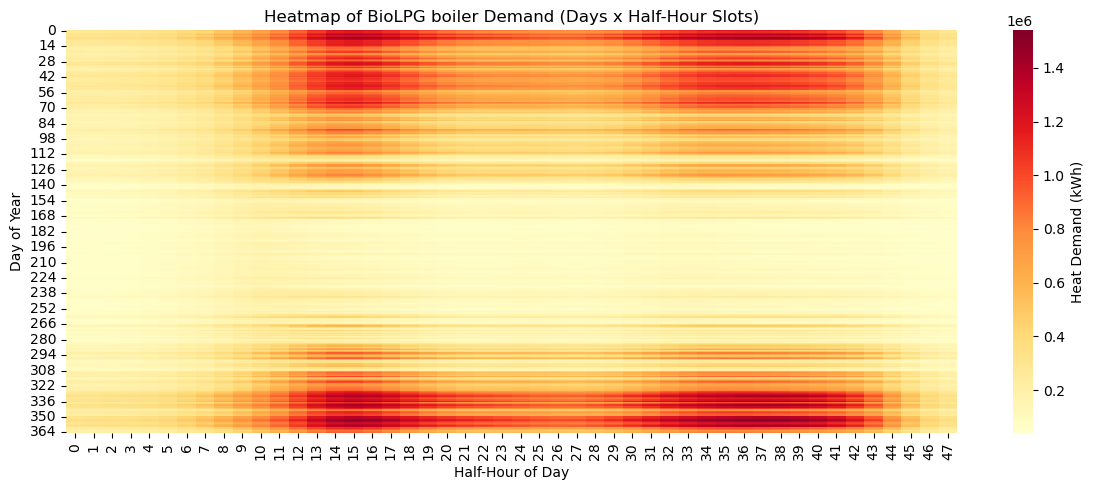

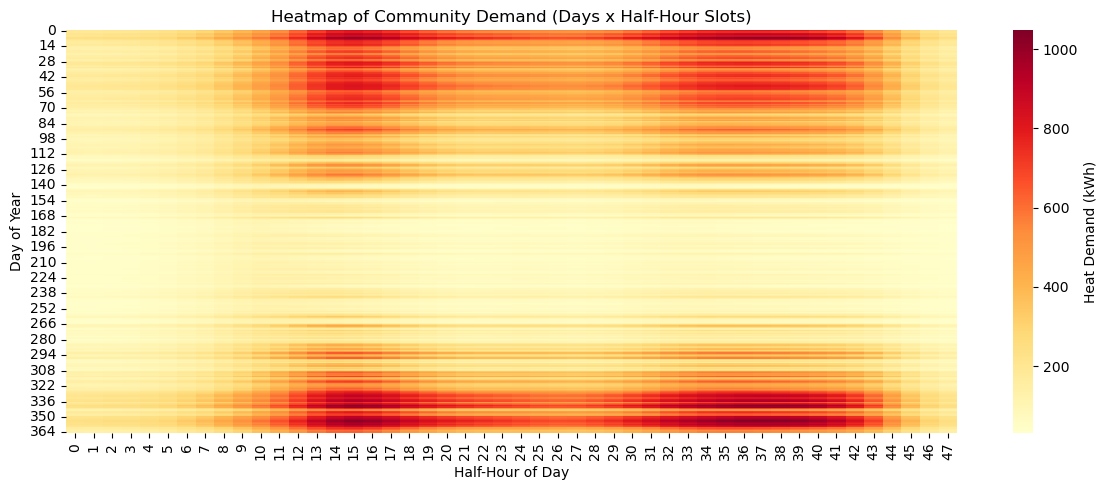

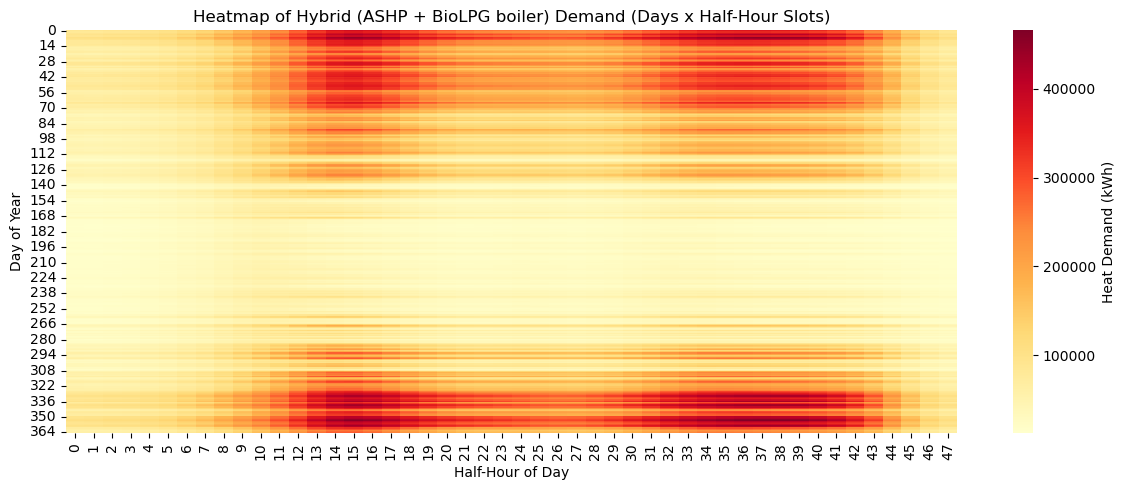

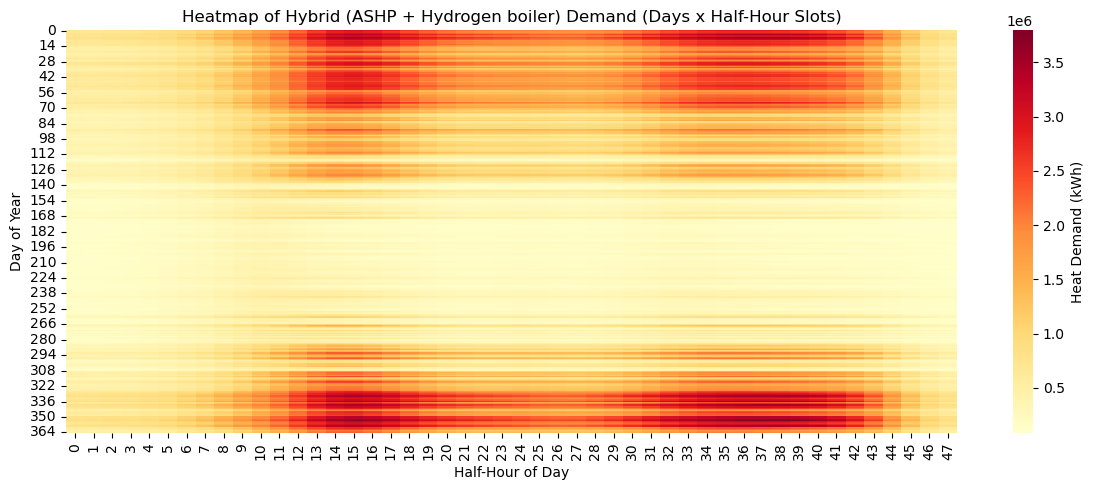

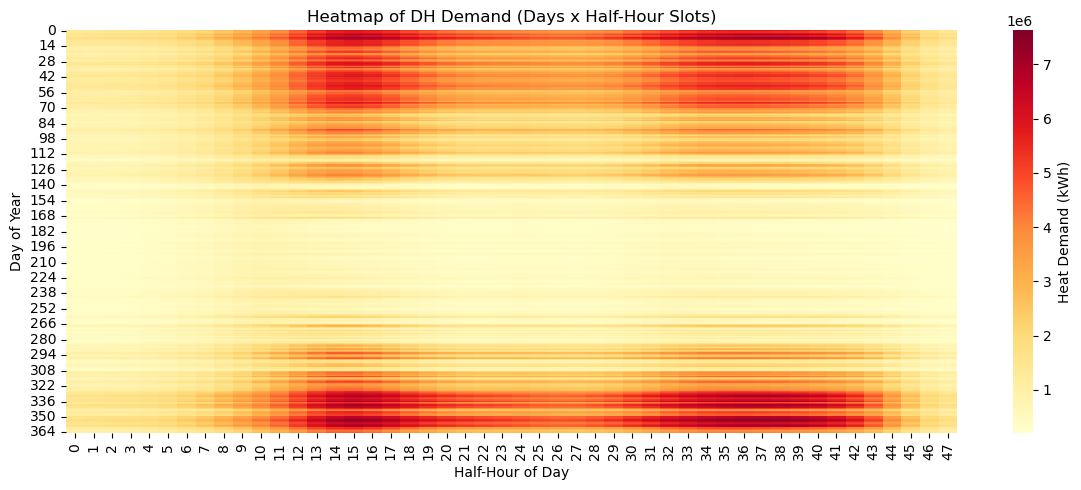

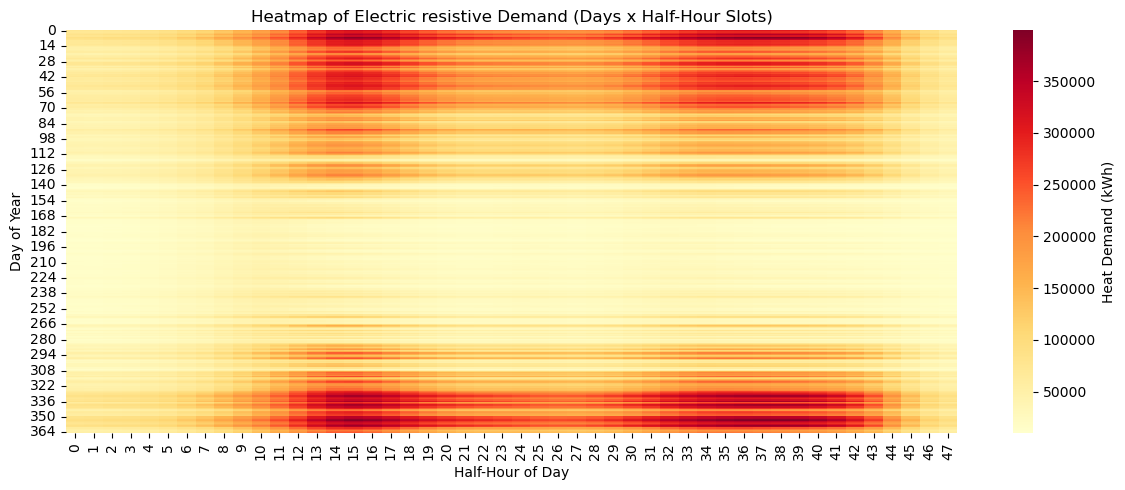

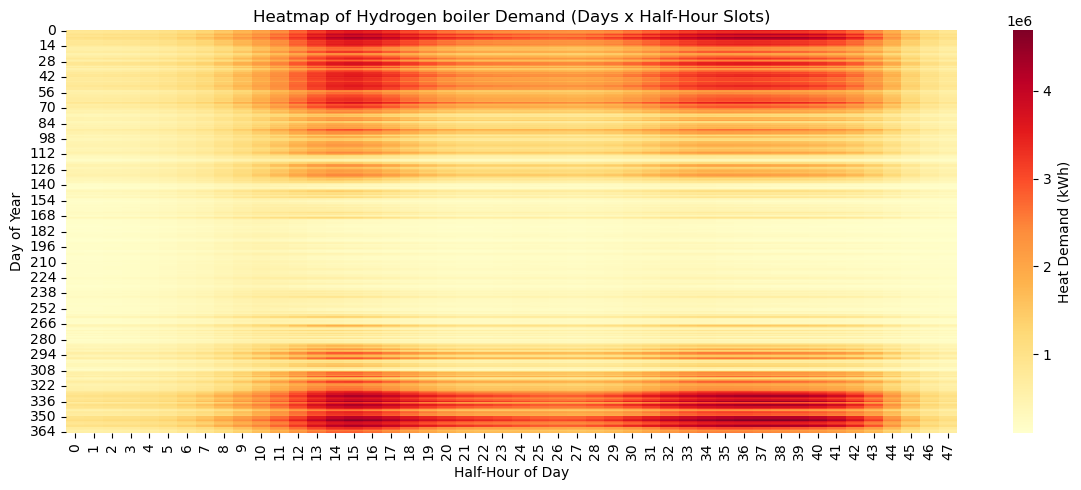

In [14]:
plot_tech_heatmaps(
    HD_profiles,
)


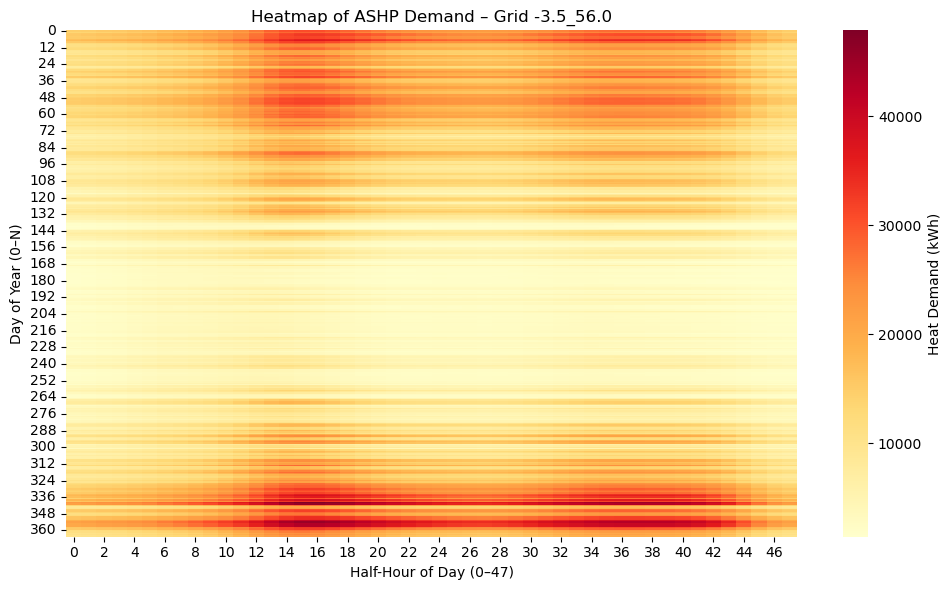

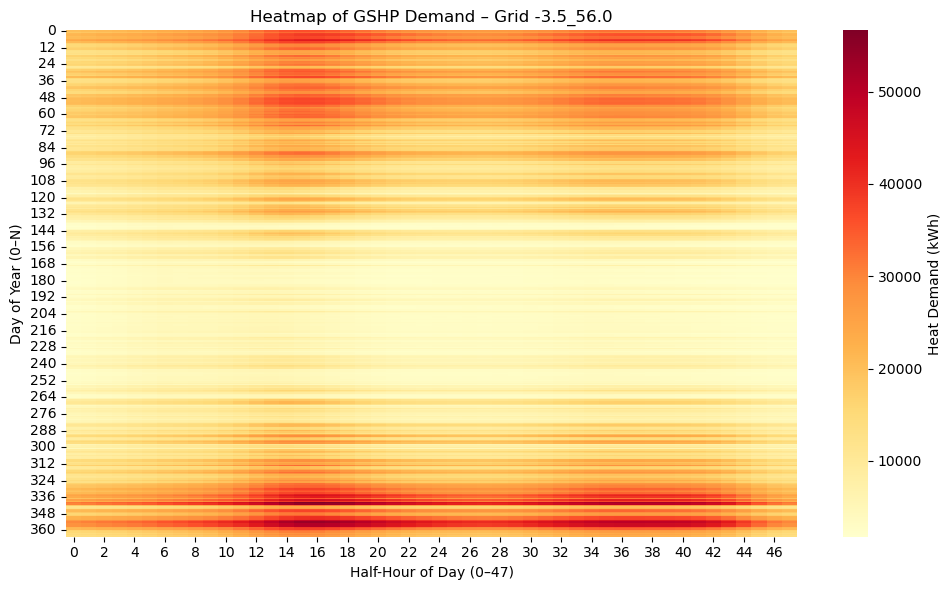

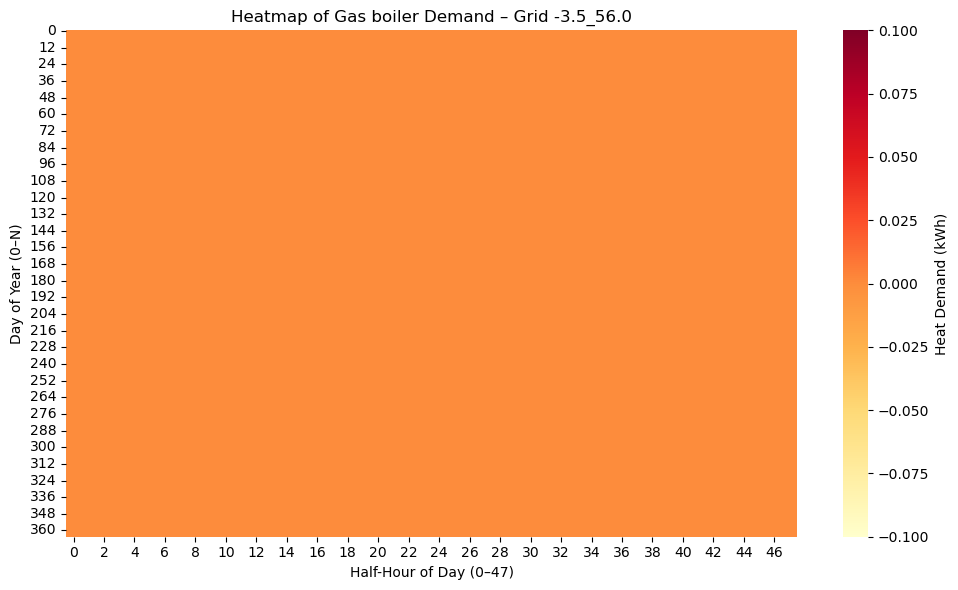

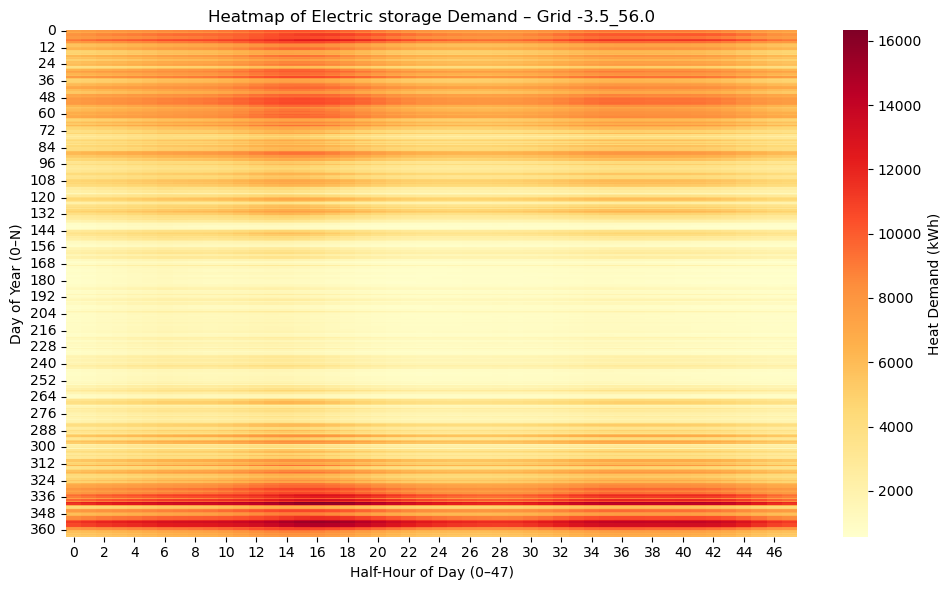

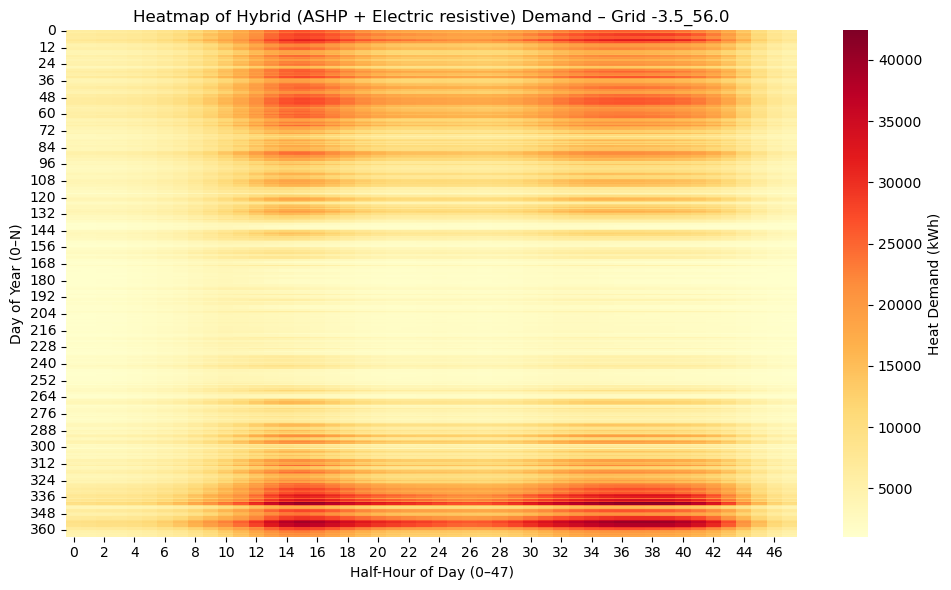

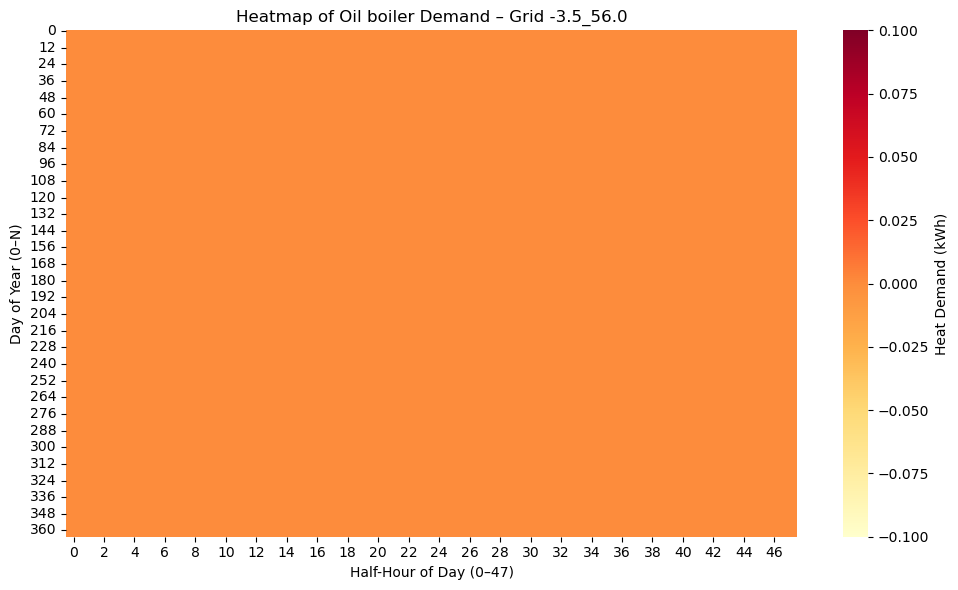

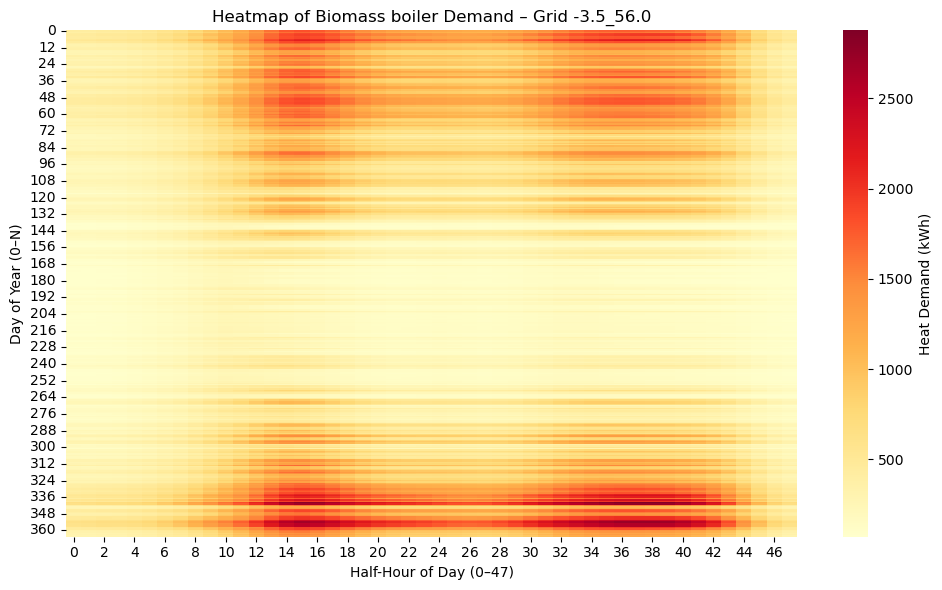

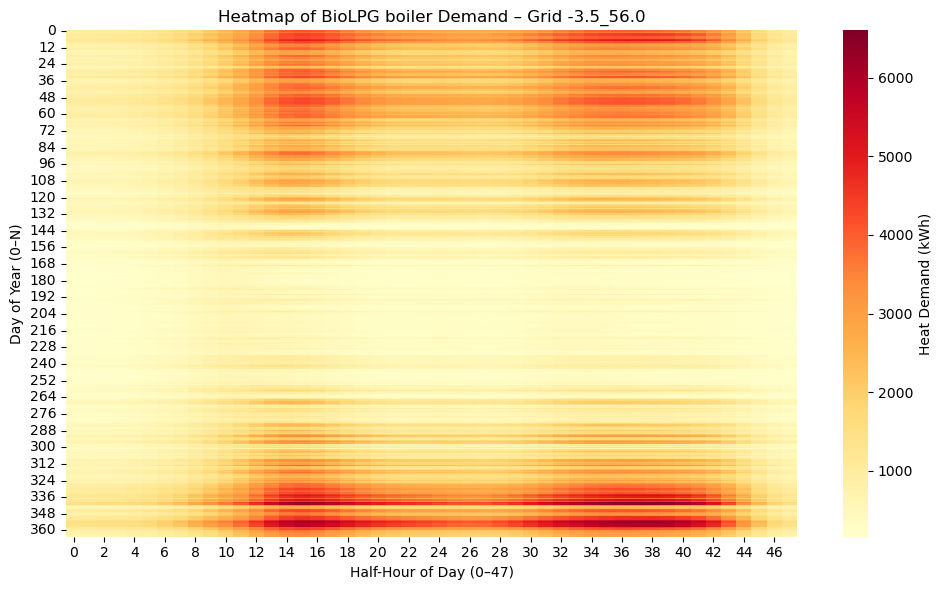

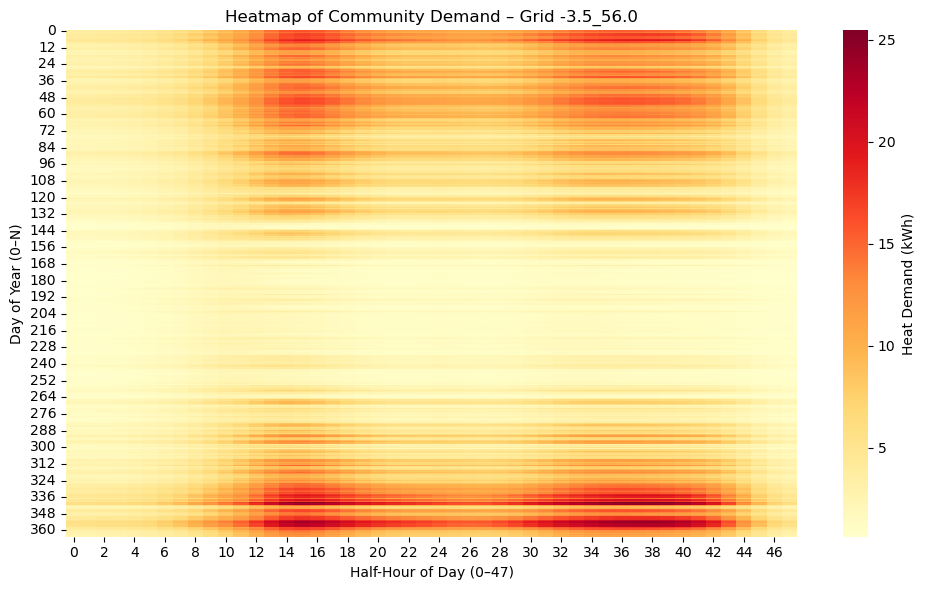

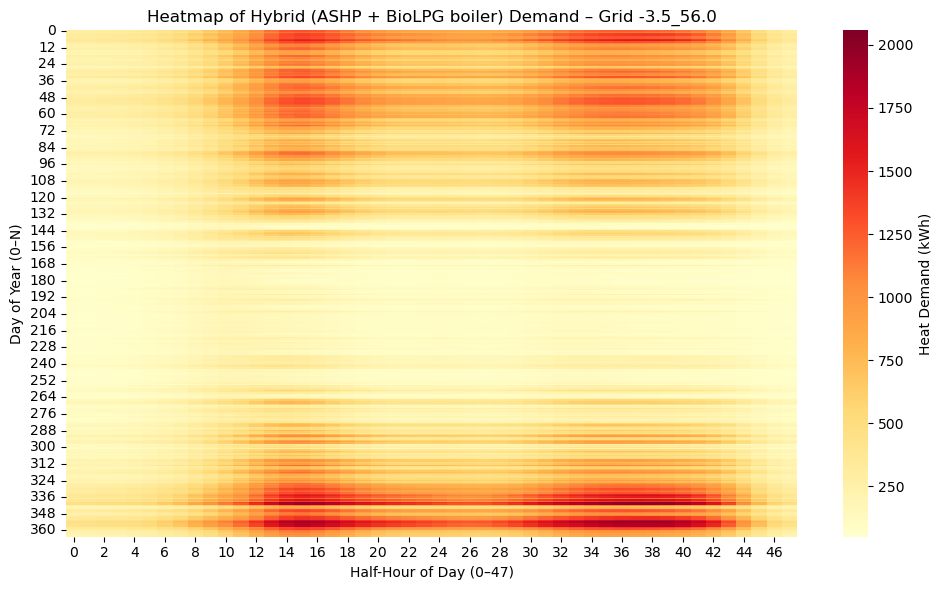

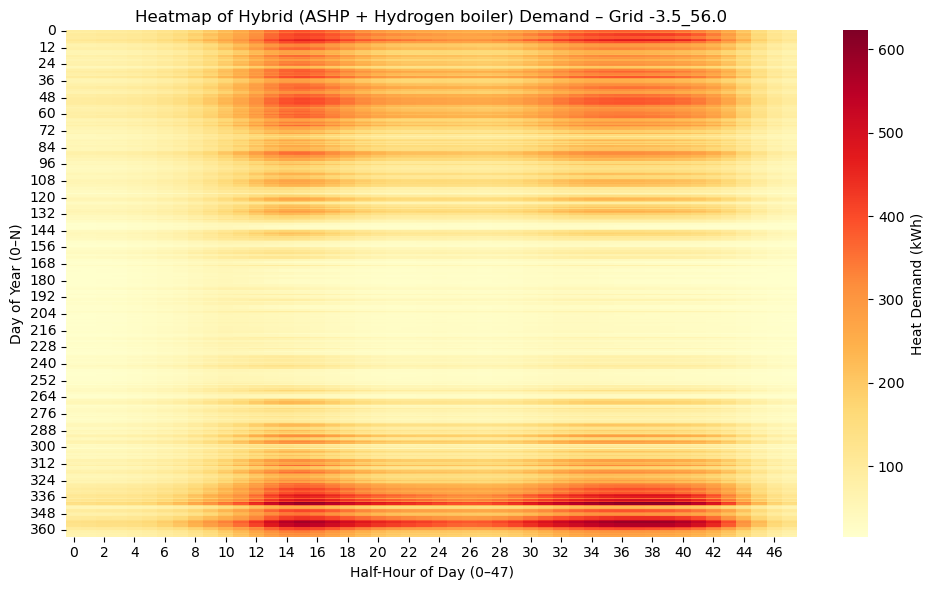

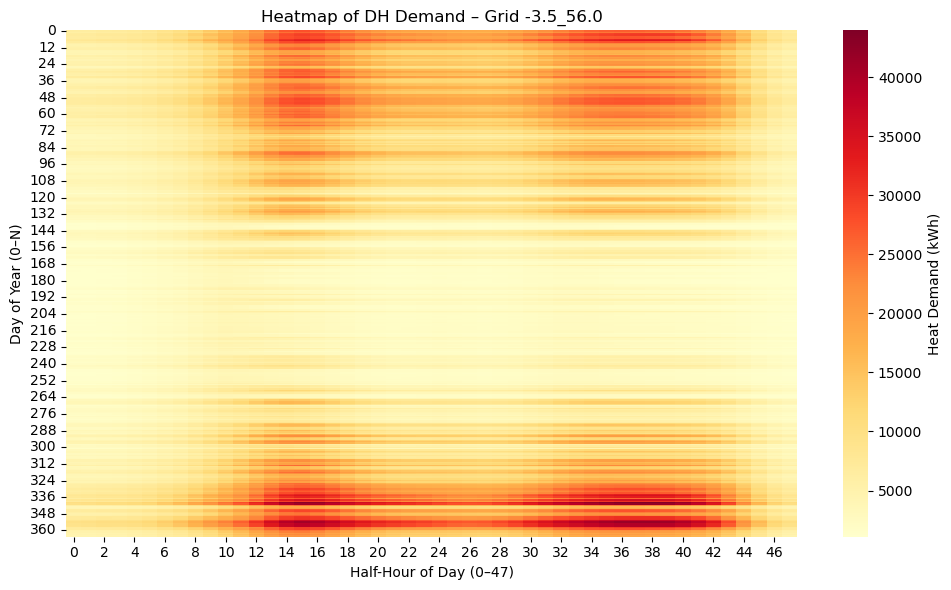

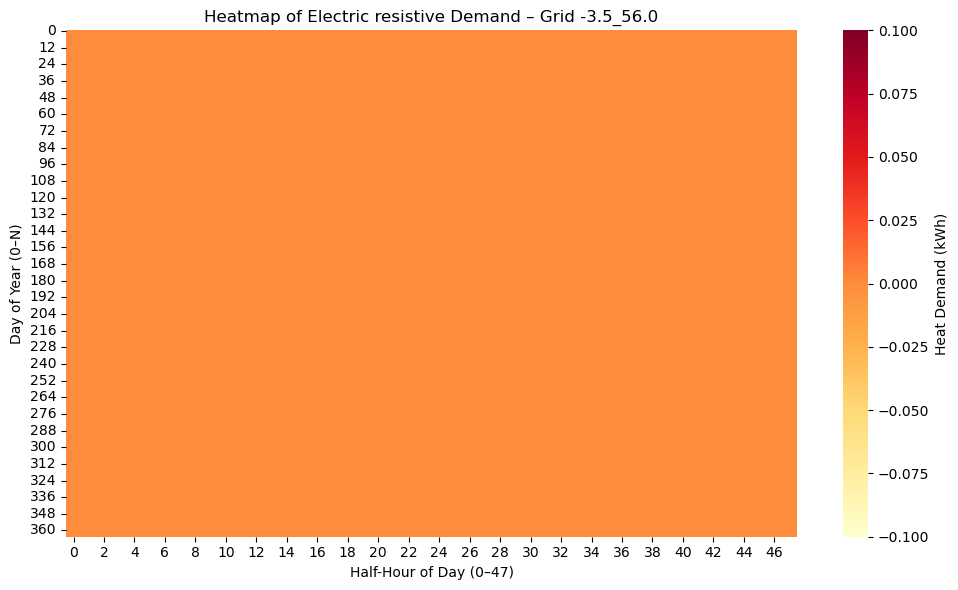

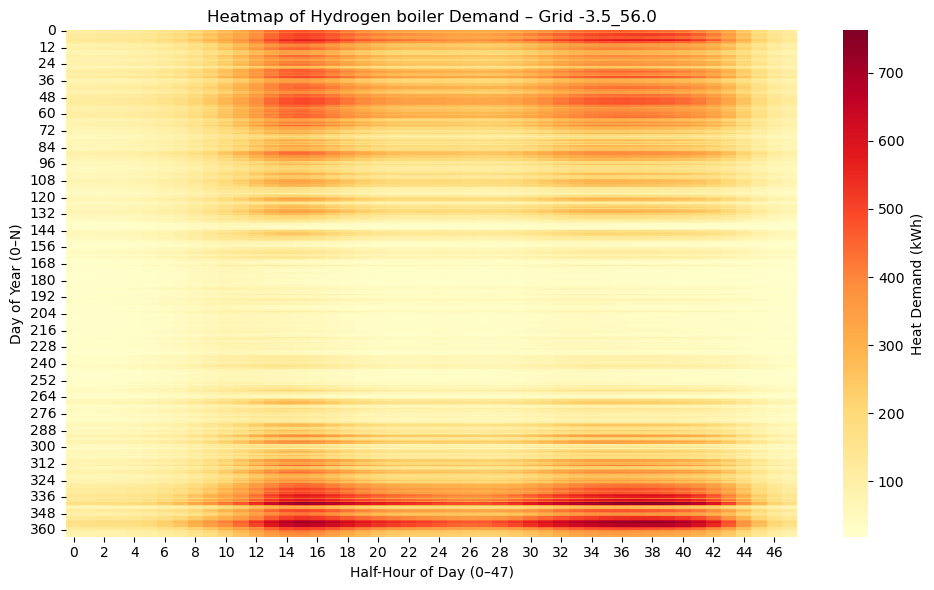

In [15]:
plot_heatmap_one_grid(
    scaled_profiles_dict=HD_profiles,
    grid_id=grid_id,
    save=False,
)